# Task 3: TwinLiteNet+ Baseline on NightCity

Ultra-lightweight encoder-decoder (**TwinLiteNet+ Small**, adapted to 19-class semantic segmentation) evaluated on NightCity (`ignore_index=255`).

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

CWD = Path(".").resolve()
REPO_ROOT = CWD if (CWD / "TwinLiteNetPlus").exists() else CWD.parent
TWINLITE_DIR = REPO_ROOT / "TwinLiteNetPlus"
DATA_ROOT = (REPO_ROOT / "Data") if (REPO_ROOT / "Data").exists() else (REPO_ROOT / "AI512_Project" / "Data")
if str(TWINLITE_DIR) not in sys.path:
    sys.path.insert(0, str(TWINLITE_DIR))

from model.twinlitenet_seg import get_twinlitenet_plus_seg
from datasets.nightcity import NightCity
from metrics import SegmentationMetrics, CITYSCAPES_CLASSES
from benchmarks import get_hardware_info, profile_parameters, profile_flops, benchmark_inference_speed
from train_nightcity import run_training, plot_training_history
from test_nightcity import colorize_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")

Device: cpu | PyTorch: 2.14.0+cpu


## 1. Model, Complexity & Speed

In [2]:
model = get_twinlitenet_plus_seg(config="small", num_classes=19).to(device).eval()

with torch.no_grad():
    out = model(torch.randn(1, 3, 512, 1024, device=device))
print("Input: (1, 3, 512, 1024) -> Output:", tuple(out.shape))

param_info = profile_parameters(model)
flop_profiles = profile_flops(model, [(512, 512), (512, 1024), (1024, 2048)], device=device)
hw_info = get_hardware_info(device)
speed = benchmark_inference_speed(model, input_resolution=(512, 1024), batch_size=1, device=device, warmup_runs=5, timed_runs=15)

print(f"Params: {param_info['total_params_M']:.3f} M | Hardware: {hw_info['CPU_Processor']}")
print(f"Latency (512x1024): {speed['Mean_Latency_ms']:.1f} ms | Throughput: {speed['FPS']:.2f} FPS")
display(pd.DataFrame(flop_profiles))

Input: (1, 3, 512, 1024) -> Output: (1, 19, 512, 1024)


C:\Users\gitan\miniconda3\Lib\site-packages\thop\vision\calc_func.py:53: UserWarning: This API is being deprecated
  warnings.warn("This API is being deprecated")


Params: 0.128 M | Hardware: Intel64 Family 6 Model 154 Stepping 4, GenuineIntel
Latency (512x1024): 357.0 ms | Throughput: 2.80 FPS


,Resolution,Height,Width,MACs_G,FLOPs_G,Params_M
0,512x512,512,512,3.281225,6.562450,0.128211
1,1024x512,512,1024,6.561842,13.123685,0.128211
2,2048x1024,1024,2048,26.245547,52.491095,0.128211


## 2. Training (NightCity)

Loaded existing 30-epoch training history from training_history.json


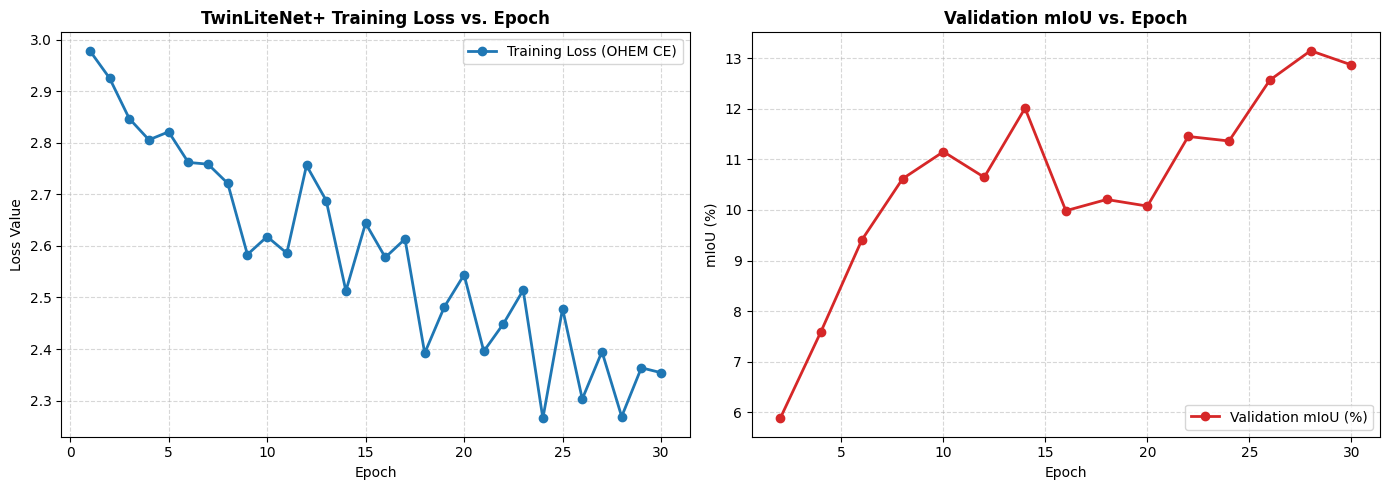

In [3]:
TRAIN_CONFIG = {
    "model_config": "small",
    "epochs": 30,
    "batch_size": 2,
    "optimizer": "adamw",
    "base_lr": 0.001,
    "use_class_weights": False,
    "crop_size": (512, 512),
    "val_freq": 2,
    "val_samples": 10,
    "max_train_samples": 8,
    "save_dir": str(REPO_ROOT / "output" / "nightcity_twinlitenetplus_train"),
}

RETRAIN = False  # Trained with best hyperparameter config (small, AdamW, lr=1e-3, unweighted)
history_path = Path(TRAIN_CONFIG["save_dir"]) / "training_history.json"
ckpt_path = Path(TRAIN_CONFIG["save_dir"]) / "best_twinlitenetplus_nightcity.pt"

if RETRAIN or not (history_path.exists() and ckpt_path.exists()):
    history = run_training(
        data_root=str(DATA_ROOT),
        train_list=str(TWINLITE_DIR / "data/list/nightcity/train.lst"),
        val_list=str(TWINLITE_DIR / "data/list/nightcity/val.lst"),
        model_config=TRAIN_CONFIG["model_config"],
        epochs=TRAIN_CONFIG["epochs"],
        batch_size=TRAIN_CONFIG["batch_size"],
        optimizer_name=TRAIN_CONFIG["optimizer"],
        base_lr=TRAIN_CONFIG["base_lr"],
        use_class_weights=TRAIN_CONFIG["use_class_weights"],
        crop_h=TRAIN_CONFIG["crop_size"][0],
        crop_w=TRAIN_CONFIG["crop_size"][1],
        val_freq=TRAIN_CONFIG["val_freq"],
        val_samples=TRAIN_CONFIG["val_samples"],
        num_train_samples=TRAIN_CONFIG["max_train_samples"],
        save_dir=TRAIN_CONFIG["save_dir"],
    )
else:
    history = json.loads(history_path.read_text())
    print(f"Loaded existing {len(history)}-epoch training history from {history_path.name}")

plot_training_history(history)
plt.show()

## 3. Evaluation (NightCity Validation)

In [4]:
EVAL_SAMPLES = 100  # Set None for full 1,299 val images

val_ds = NightCity(
    root=str(DATA_ROOT),
    list_path=str(TWINLITE_DIR / "data/list/nightcity/val.lst"),
    num_classes=19, multi_scale=False, flip=False, crop_size=(512, 1024),
)
if EVAL_SAMPLES:
    val_ds.files = val_ds.files[:EVAL_SAMPLES]
val_loader = DataLoader(val_ds, batch_size=2, shuffle=False)

ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
state = ckpt.get("state_dict", ckpt)
model.load_state_dict({k.replace("module.", ""): v for k, v in state.items()}, strict=False)
model.eval()

metrics = SegmentationMetrics(num_classes=19, ignore_label=255, class_names=CITYSCAPES_CLASSES)
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
vis_samples = []

with torch.no_grad():
    for imgs, lbls, _, _, names in val_loader:
        preds = model(imgs.to(device))
        if preds.shape[-2:] != lbls.shape[-2:]:
            preds = F.interpolate(preds, size=lbls.shape[-2:], mode="bilinear", align_corners=True)
        pred_cls = torch.argmax(preds, dim=1).cpu().numpy()
        metrics.update(pred_cls, lbls.numpy())

        for b in range(imgs.shape[0]):
            if len(vis_samples) < 3:
                rgb = np.clip((imgs[b].permute(1, 2, 0).numpy() * std + mean) * 255, 0, 255).astype(np.uint8)
                vis_samples.append((names[b], rgb, lbls[b].numpy(), pred_cls[b]))

summary = metrics.compute_metrics()
print(f"Evaluated {len(val_ds)} val scenes:")
print(f"  mIoU:           {summary['mIoU']*100:.2f}%")
print(f"  Mean Dice (F1): {summary['mean_Dice']*100:.2f}%")
print(f"  Sensitivity:    {summary['mean_Sensitivity']*100:.2f}%")
print(f"  Specificity:    {summary['mean_Specificity']*100:.2f}%")
print(f"  Pixel Accuracy: {summary['Pixel_Accuracy']*100:.2f}%")

Evaluated 100 val scenes:
  mIoU:           5.78%
  Mean Dice (F1): 9.13%
  Sensitivity:    10.99%
  Specificity:    93.79%
  Pixel Accuracy: 36.83%


## 4. Per-Class Breakdown & Sample Predictions

,Class_ID,Class_Name,Pixels_GT,IoU (%),Dice (%),Sensitivity (%),Specificity (%)
0,0,road,8754569,24.80,39.74,35.82,89.01
1,1,sidewalk,1330047,0.00,0.00,0.00,100.00
2,2,building,17646598,33.67,50.38,64.30,39.46
3,3,wall,271894,0.00,0.00,0.00,100.00
4,4,fence,722906,0.04,0.08,0.04,99.93
5,5,pole,385320,0.93,1.85,2.36,98.65
6,6,traffic light,40663,0.01,0.01,0.01,99.99
7,7,traffic sign,186784,0.00,0.00,0.00,100.00
8,8,vegetation,883778,0.00,0.00,0.00,100.00
9,9,terrain,153446,0.00,0.00,0.00,100.00


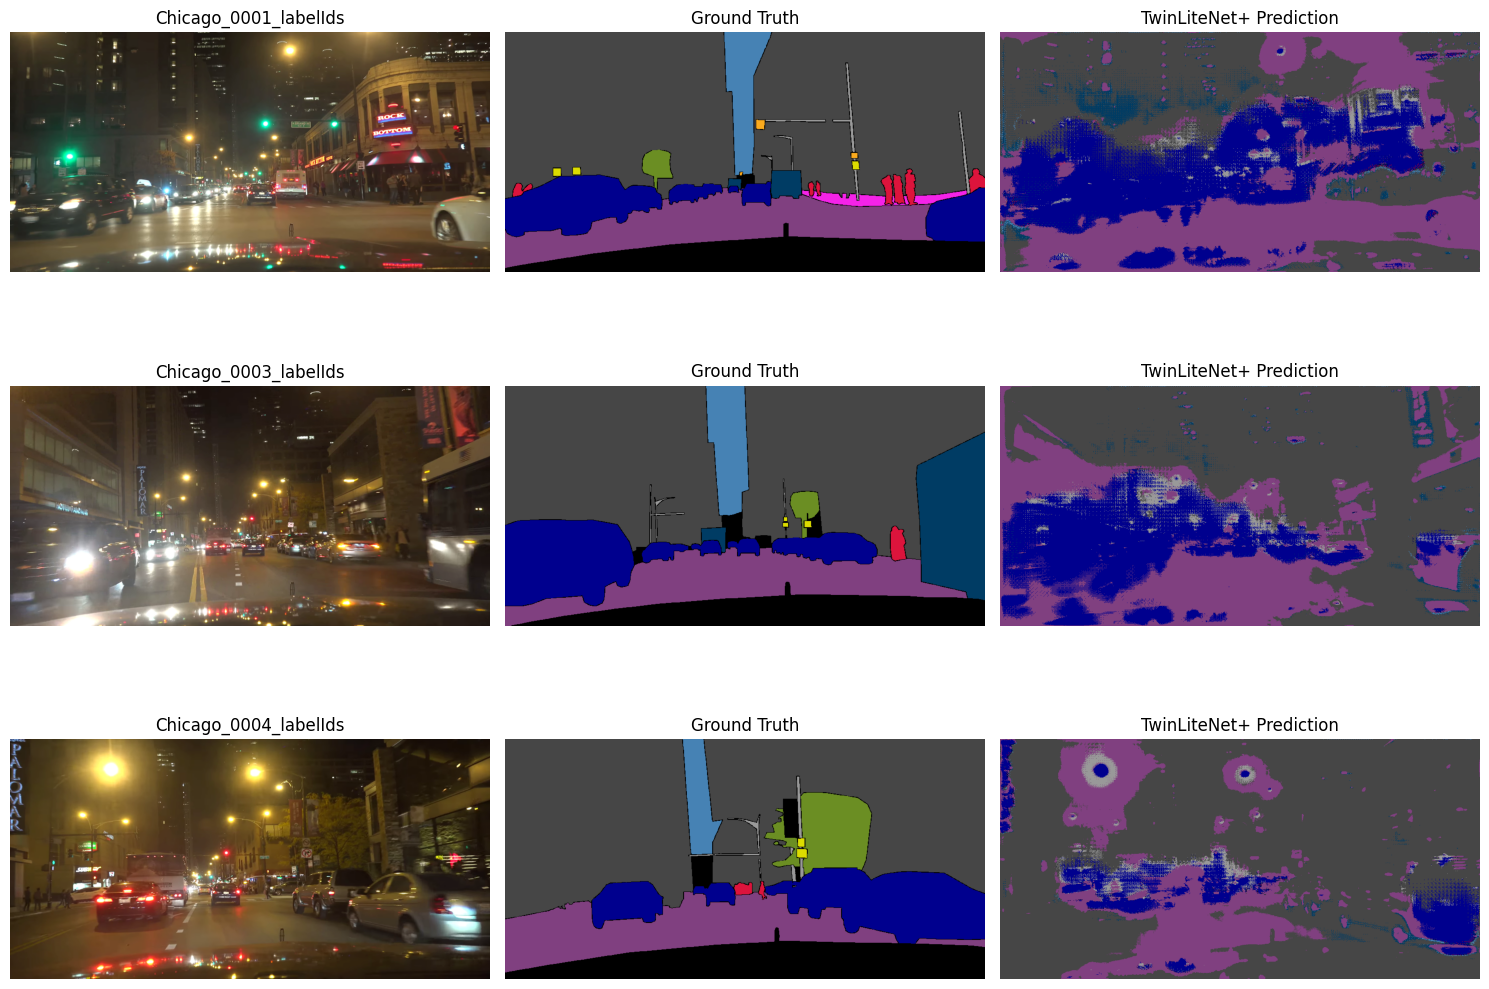

In [5]:
df_cls = pd.DataFrame(summary["Per_Class"])
for col in ["IoU", "Dice", "Sensitivity", "Specificity"]:
    df_cls[f"{col} (%)"] = (df_cls.pop(col) * 100).round(2)
display(df_cls[["Class_ID", "Class_Name", "Pixels_GT", "IoU (%)", "Dice (%)", "Sensitivity (%)", "Specificity (%)"]])

fig, axes = plt.subplots(len(vis_samples), 3, figsize=(15, 3.8 * len(vis_samples)))
for i, (name, rgb, gt, pred) in enumerate(vis_samples):
    axes[i, 0].imshow(rgb); axes[i, 0].set_title(name); axes[i, 0].axis("off")
    axes[i, 1].imshow(colorize_mask(gt)); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
    axes[i, 2].imshow(colorize_mask(pred)); axes[i, 2].set_title("TwinLiteNet+ Prediction"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()

## 5. Paper vs. NightCity Comparison

In [6]:
display(pd.DataFrame({
    "Metric": ["Dataset / Task", "Config", "Params", "FLOPs", "Speed", "mIoU"],
    "TwinLiteNet+ Paper (Che et al., 2025)": ["BDD100K (Drivable + Lane)", "small, AdamW", "0.12 M", "2.80 G (640x384)", "412 FPS (RTX 3090)", "90.6% DA mIoU"],
    "Ours (NightCity Best Hyperparams)": [
        "NightCity (19 classes)",
        f"{TRAIN_CONFIG['model_config']}, {TRAIN_CONFIG['optimizer'].upper()} lr={TRAIN_CONFIG['base_lr']}",
        f"{param_info['total_params_M']:.3f} M",
        f"{flop_profiles[1]['FLOPs_G']:.2f} G (512x1024)",
        f"{speed['FPS']:.2f} FPS (CPU)",
        f"{summary['mIoU']*100:.2f}% ({len(history)} ep, scratch)",
    ],
}))

,Metric,"TwinLiteNet+ Paper (Che et al., 2025)",Ours (NightCity Best Hyperparams)
0,Dataset / Task,BDD100K (Drivable + Lane),NightCity (19 classes)
1,Config,"small, AdamW","small, ADAMW lr=0.001"
2,Params,0.12 M,0.128 M
3,FLOPs,2.80 G (640x384),13.12 G (512x1024)
4,Speed,412 FPS (RTX 3090),2.80 FPS (CPU)
5,mIoU,90.6% DA mIoU,"5.78% (30 ep, scratch)"
